In [1]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import sys
import torch
import numpy as np
import random
import os
sys.path.append('..')
from models.mnist_autoencoder import MNISTAutoencoder
from trainers.autoencoder_trainer import AutoencoderTrainer
from models.mnist_classifier import MNISTClassifier
from trainers.classifier_trainer import ClassifierTrainer

In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)  

In [3]:
#data_path = "/datasets/cv_datasets/data"
data_path = "../data"

train_transform = transforms.Compose([
    transforms.RandomRotation(degrees=5),
    transforms.RandomAffine(0, translate=(0.05, 0.05)),
    transforms.ToTensor()
])
val_transform = transforms.ToTensor()
test_transform = transforms.ToTensor()

full_train_dataset = datasets.MNIST(root=data_path, train=True, download=False)
test_dataset = datasets.MNIST(root=data_path, train=False, download=False)


train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_subset, val_subset = torch.utils.data.random_split(
    full_train_dataset, [train_size, val_size]
)
class TransformedSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

train_dataset = TransformedSubset(train_subset, train_transform)
val_dataset = TransformedSubset(val_subset, val_transform)
test_dataset = TransformedSubset(test_dataset, test_transform)


train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

autoencoder_l1_loss = MNISTAutoencoder(latent_dim=128).to('cuda')
autoencoder_trainer = AutoencoderTrainer(
model=autoencoder_l1_loss,
train_loader=train_loader,
val_loader=val_loader,
test_loader = test_loader,
criterion=torch.nn.L1Loss(),
device='cuda',
lr=1e-4,
num_epochs=60,
weight_decay=1e-4,
)

In [5]:
autoencoder_trainer.train()

Epoch [1] - Train Loss: 0.0440, Val Loss: 0.0292, Test Loss: 0.0290
              Train L1: 0.0440,  Val L1: 0.0292, Test L1: 0.0290
Epoch [2] - Train Loss: 0.0255, Val Loss: 0.0201, Test Loss: 0.0199
              Train L1: 0.0255,  Val L1: 0.0201, Test L1: 0.0199
Epoch [3] - Train Loss: 0.0199, Val Loss: 0.0172, Test Loss: 0.0170
              Train L1: 0.0199,  Val L1: 0.0172, Test L1: 0.0170
Epoch [4] - Train Loss: 0.0173, Val Loss: 0.0151, Test Loss: 0.0149
              Train L1: 0.0173,  Val L1: 0.0151, Test L1: 0.0149
Epoch [5] - Train Loss: 0.0158, Val Loss: 0.0141, Test Loss: 0.0139
              Train L1: 0.0158,  Val L1: 0.0141, Test L1: 0.0139
Epoch [6] - Train Loss: 0.0148, Val Loss: 0.0132, Test Loss: 0.0131
              Train L1: 0.0148,  Val L1: 0.0132, Test L1: 0.0131
Epoch [7] - Train Loss: 0.0141, Val Loss: 0.0125, Test Loss: 0.0124
              Train L1: 0.0141,  Val L1: 0.0125, Test L1: 0.0124
Epoch [8] - Train Loss: 0.0136, Val Loss: 0.0123, Test Loss: 0.0121
 

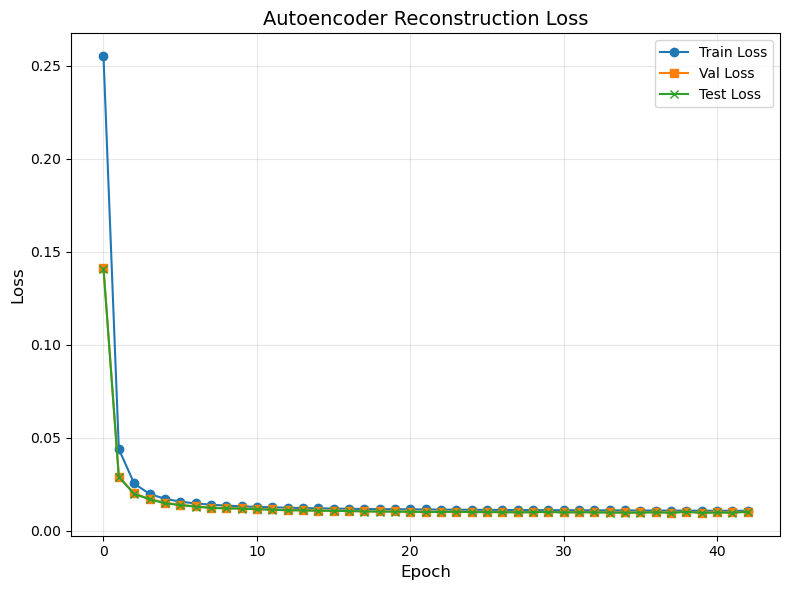

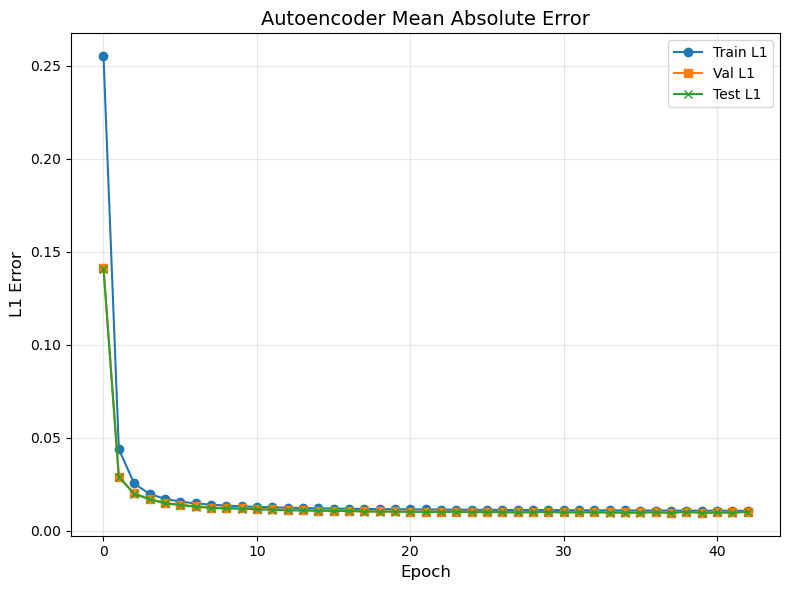

=== Final Autoencoder Metrics ===
Train ReconLoss: 0.0108
Val   ReconLoss: 0.0104
Test  ReconLoss: 0.0103
Train L1: 0.0108
Val   L1: 0.0104
Test  L1: 0.0103


In [6]:
autoencoder_trainer.plot_metrics()

In [13]:
classifier2 = MNISTClassifier(latent_dim=128, num_classes=10)
classifier_trainer2 = ClassifierTrainer(
encoder=autoencoder_l1_loss.encoder,
classifier=classifier2,
train_loader=train_loader,
val_loader=val_loader,
test_loader =test_loader,
num_epochs=40,
patience=3
)
classifier_trainer2.train() 
print("Autoencoder training done.")

Epoch [1] - TrainAcc: 0.7608, ValAcc: 0.8981, TestAcc: 0.9134 | ValLoss: 0.3695
Epoch [2] - TrainAcc: 0.8641, ValAcc: 0.9209, TestAcc: 0.9277 | ValLoss: 0.2925
Epoch [3] - TrainAcc: 0.8909, ValAcc: 0.9344, TestAcc: 0.9421 | ValLoss: 0.2422
Epoch [4] - TrainAcc: 0.9095, ValAcc: 0.9431, TestAcc: 0.9503 | ValLoss: 0.2108
Epoch [5] - TrainAcc: 0.9259, ValAcc: 0.9499, TestAcc: 0.9570 | ValLoss: 0.1834
Epoch [6] - TrainAcc: 0.9361, ValAcc: 0.9550, TestAcc: 0.9626 | ValLoss: 0.1609
Epoch [7] - TrainAcc: 0.9430, ValAcc: 0.9607, TestAcc: 0.9673 | ValLoss: 0.1440
Epoch [8] - TrainAcc: 0.9502, ValAcc: 0.9649, TestAcc: 0.9677 | ValLoss: 0.1308
Epoch [9] - TrainAcc: 0.9527, ValAcc: 0.9675, TestAcc: 0.9697 | ValLoss: 0.1209
Epoch [10] - TrainAcc: 0.9562, ValAcc: 0.9692, TestAcc: 0.9712 | ValLoss: 0.1143
Epoch [11] - TrainAcc: 0.9591, ValAcc: 0.9704, TestAcc: 0.9734 | ValLoss: 0.1077
Epoch [12] - TrainAcc: 0.9613, ValAcc: 0.9712, TestAcc: 0.9727 | ValLoss: 0.1040
Epoch [13] - TrainAcc: 0.9631, ValAcc

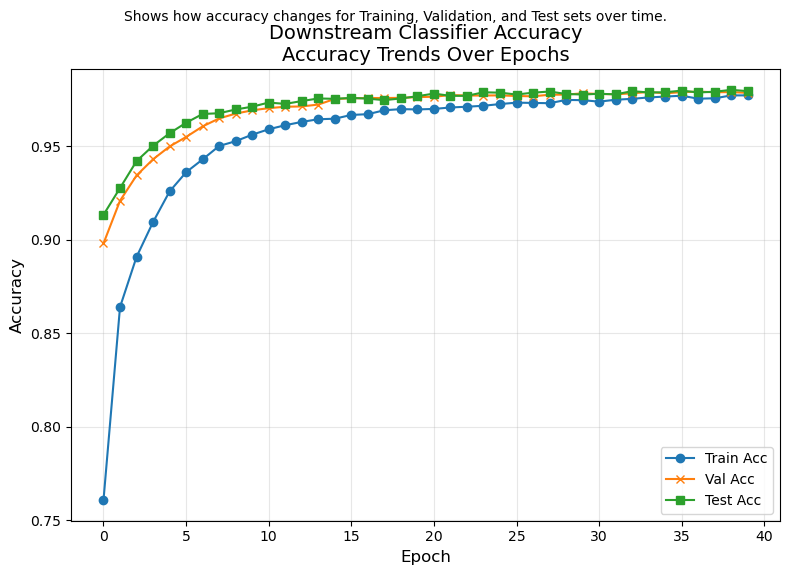

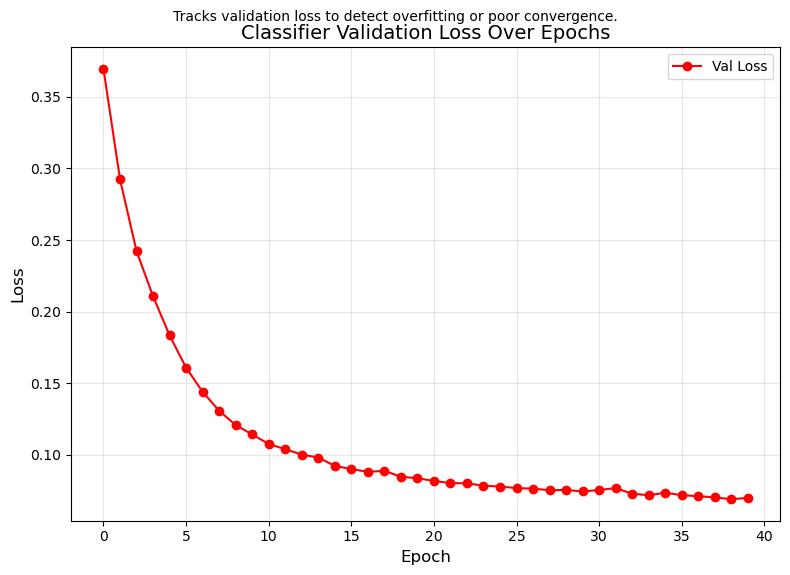

=== Final Classifier Metrics ===
Val Loss: 0.0700
Train Acc: 97.72%
Val   Acc: 97.86%
Test  Acc: 97.95%


In [14]:
classifier_trainer2.plot_metrics()

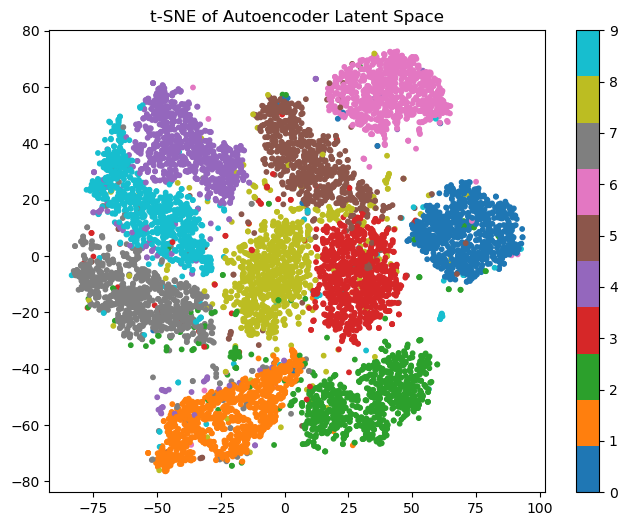

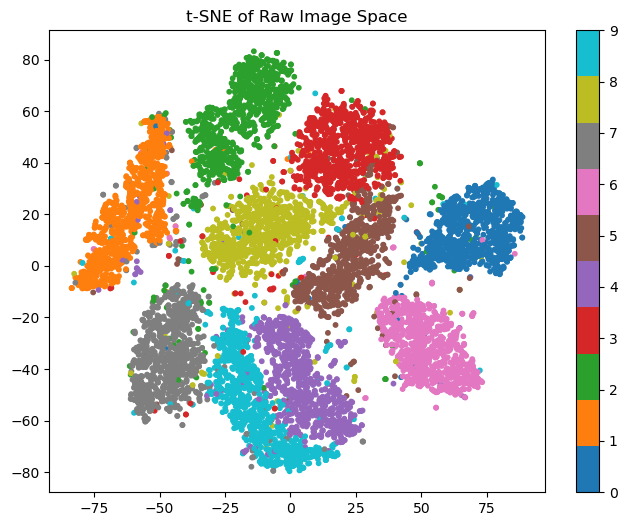

In [16]:
from utils import plot_tsne_autoencoder
plot_tsne_autoencoder(autoencoder_l1_loss, test_loader, device='cuda')

